<a href="https://colab.research.google.com/github/Resh-ma050706/Deep-learning/blob/main/24BAD097_EXP_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os, re, random, tarfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# ------------------------------------------------------------------
# ENTER YOUR DETAILS HERE (printed in every part of the experiment)
# ------------------------------------------------------------------
STUDENT_NAME = "S.RESHMA"
ROLL_NOS     = "24BAD097"

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("Student :", STUDENT_NAME)
print("Roll No :", ROLL_NOS)
print("TensorFlow version:", tf.__version__)
print("GPU available     :", tf.config.list_physical_devices('GPU'))

Student : S.RESHMA
Roll No : 24BAD097
TensorFlow version: 2.21.0
GPU available     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## PART A: DATASET PREPARATION

In [7]:
print("PART A  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

# ---- 1. Load the IMDB Movie Reviews dataset (50,000 labelled reviews) ----
url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
archive = keras.utils.get_file("aclImdb_v1", url, untar=True,
                               cache_dir=".", cache_subdir="")

# If untarred locally to the root or subfolders, let's find the correct aclImdb folder
if os.path.exists("./aclImdb"):
    DATA_DIR = "./aclImdb"
elif os.path.exists("./datasets/aclImdb"):
    DATA_DIR = "./datasets/aclImdb"
else:
    # Fallback to scanning where it could have extracted
    DATA_DIR = "./aclImdb"
    for root, dirs, files in os.walk("."):
        if "aclImdb" in dirs:
            DATA_DIR = os.path.join(root, "aclImdb")
            break

print("Dataset folder:", DATA_DIR)
print("Contents      :", os.listdir(DATA_DIR))

def load_split(split):
    texts, labels = [], []
    for label_name, label in [("neg", 0), ("pos", 1)]:
        folder = os.path.join(DATA_DIR, split, label_name)
        for fname in os.listdir(folder):
            if fname.endswith(".txt"):
                with open(os.path.join(folder, fname), encoding="utf-8") as f:
                    texts.append(f.read())
                labels.append(label)
    df = pd.DataFrame({"review": texts, "sentiment": labels})
    return df.sample(frac=1, random_state=SEED).reset_index(drop=True)   # shuffle

train_df = load_split("train")
test_df  = load_split("test")
print("\nTrain reviews:", len(train_df), "| Test reviews:", len(test_df))

PART A  |  Roll No(s): 24BAD097
------------------------------------------------------------
Dataset folder: ./aclImdb_v1/aclImdb
Contents      : ['imdb.vocab', 'test', 'train', 'README', 'imdbEr.txt']

Train reviews: 25000 | Test reviews: 25000


PART A  |  Roll No(s): 24BAD097
------------------------------------------------------------
Classes: 0 -> Negative, 1 -> Positive

Class distribution (train):
sentiment
Negative    12500
Positive    12500
Name: count, dtype: int64 

Sample 1 | Label: Negative
Wow. I thought this might be insipid but it was even worse than I imagined! Sometimes I like to watch a good "car-crash" movie: those that are so bad that you can't look away because you want to see how bad they can possibly get. This is really the only reason I could leave the television on - morbi ...

Sample 2 | Label: Positive
<br /><br />I'm sure things didn't exactly go the same way in the real life of Homer Hickam as they did in the film adaptation of his book, Rocket Boys, but the movie "October Sky" (an anagram of the book's title) is good enough to stand alone. I have not read Hickam's memoirs, but I am still able t ...

Sample 3 | Label: Negative
*****probably minor spoilers******<br /><br />I cant say i liked it, but 

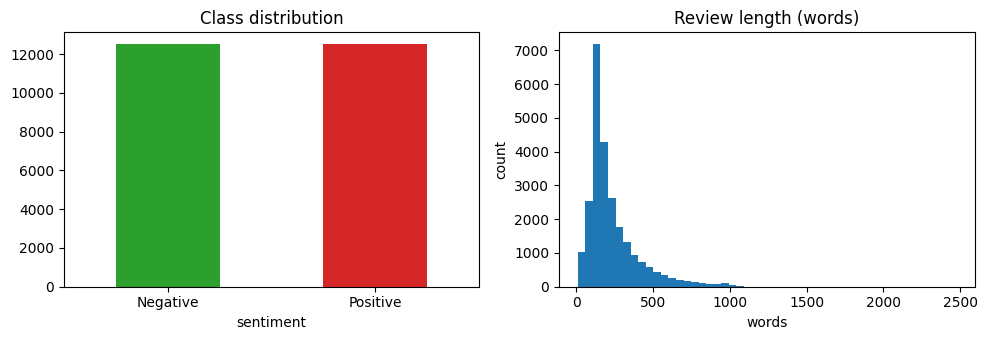

In [8]:
# ---- 2 & 3. Explore dataset, view samples, identify the sentiment classes ----
print("PART A  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

label_names = {0: "Negative", 1: "Positive"}
print("Classes: 0 -> Negative, 1 -> Positive\n")
print("Class distribution (train):")
print(train_df["sentiment"].map(label_names).value_counts(), "\n")

for i in range(3):
    print(f"Sample {i+1} | Label: {label_names[train_df.sentiment[i]]}")
    print(train_df.review[i][:300], "...\n")

train_df["n_words"] = train_df["review"].str.split().str.len()
print(train_df["n_words"].describe())

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
train_df["sentiment"].map(label_names).value_counts().plot(kind="bar", color=["tab:green", "tab:red"])
plt.title("Class distribution"); plt.xticks(rotation=0)
plt.subplot(1, 2, 2)
plt.hist(train_df["n_words"], bins=50, color="tab:blue")
plt.title("Review length (words)"); plt.xlabel("words"); plt.ylabel("count")
plt.tight_layout(); plt.show()

In [9]:
# ---- 4 & 5. Text preprocessing: lowercase, remove HTML tags / symbols ----
print("PART A  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

def clean_text(text):
    text = text.lower()                          # lowercase
    text = re.sub(r"<br\s*/?>", " ", text)       # remove HTML line breaks
    text = re.sub(r"[^a-z\s']", " ", text)       # keep only letters, spaces, apostrophes
    text = re.sub(r"\s+", " ", text).strip()     # collapse extra spaces
    return text

train_df["clean"] = train_df["review"].apply(clean_text)
test_df["clean"]  = test_df["review"].apply(clean_text)

print("BEFORE:", train_df.review[0][:200])
print("AFTER :", train_df.clean[0][:200])

# ---- 6. Tokenization (split reviews into words) ----
train_tokens = [t.split() for t in train_df["clean"]]
test_tokens  = [t.split() for t in test_df["clean"]]
print("\nTokens of review 0:", train_tokens[0][:15])

PART A  |  Roll No(s): 24BAD097
------------------------------------------------------------
BEFORE: Wow. I thought this might be insipid but it was even worse than I imagined! Sometimes I like to watch a good "car-crash" movie: those that are so bad that you can't look away because you want to see h
AFTER : wow i thought this might be insipid but it was even worse than i imagined sometimes i like to watch a good car crash movie those that are so bad that you can't look away because you want to see how ba

Tokens of review 0: ['wow', 'i', 'thought', 'this', 'might', 'be', 'insipid', 'but', 'it', 'was', 'even', 'worse', 'than', 'i', 'imagined']


In [10]:
# ---- 7. Build vocabulary and assign unique integer indices ----
print("PART A  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

VOCAB_SIZE = 10000          # keep the 10,000 most frequent words (incl. PAD & OOV)
MAX_LEN    = 200            # every review is padded / truncated to 200 tokens

counter = Counter(tok for review in train_tokens for tok in review)
print("Unique words in training data:", len(counter))

word_index = {"<PAD>": 0, "<OOV>": 1}
for word, _ in counter.most_common(VOCAB_SIZE - 2):
    word_index[word] = len(word_index)
index_word = {i: w for w, i in word_index.items()}

print("Vocabulary size:", len(word_index))
print("Sample entries :", list(word_index.items())[:12])

# ---- 8. Convert text reviews into numerical sequences ----
def encode(tokens):
    return [word_index.get(tok, word_index["<OOV>"]) for tok in tokens]

train_seq = [encode(t) for t in train_tokens]
test_seq  = [encode(t) for t in test_tokens]
print("\nReview 0 as integers:", train_seq[0][:15])
print("Decoded back        :", " ".join(index_word[i] for i in train_seq[0][:15]))

PART A  |  Roll No(s): 24BAD097
------------------------------------------------------------
Unique words in training data: 85680
Vocabulary size: 10000
Sample entries : [('<PAD>', 0), ('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('in', 8), ('it', 9), ('i', 10), ('this', 11)]

Review 0 as integers: [1304, 10, 194, 11, 235, 27, 5466, 18, 9, 13, 57, 429, 71, 10, 3741]
Decoded back        : wow i thought this might be insipid but it was even worse than i imagined


In [11]:
# ---- 9. Sequence padding (equal length inputs) ----
print("PART A  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

X_full = keras.utils.pad_sequences(train_seq, maxlen=MAX_LEN, padding="pre", truncating="post")
X_test = keras.utils.pad_sequences(test_seq,  maxlen=MAX_LEN, padding="pre", truncating="post")
y_full = train_df["sentiment"].values
y_test = test_df["sentiment"].values

print("Padded shape :", X_full.shape)
print("Review 0 (padded):", X_full[0][-20:], "...")

# ---- 10. Split into training and validation / testing datasets ----
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, random_state=SEED, stratify=y_full)

print("\nTraining set  :", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape,   y_val.shape)
print("Test set      :", X_test.shape,  y_test.shape)

PART A  |  Roll No(s): 24BAD097
------------------------------------------------------------
Padded shape : (25000, 200)
Review 0 (padded): [  10  216    9   20  243   40  700   10  586   44   11    7  135 3686
    1   45   66 1101 1543   73] ...

Training set  : (20000, 200) (20000,)
Validation set: (5000, 200) (5000,)
Test set      : (25000, 200) (25000,)


---
## PART B: IMPLEMENTING THE LSTM MODEL

In [12]:
print("PART B  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

EMBED_DIM  = 128
LSTM_UNITS = 64

model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, name="embedding"),   # words -> dense vectors
    layers.LSTM(LSTM_UNITS, name="lstm"),                                             # learns sequential dependencies
    layers.Dropout(0.3, name="dropout"),                                              # reduces overfitting
    layers.Dense(1, activation="sigmoid", name="output")                              # P(positive)
], name="LSTM_Sentiment_Model")

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy"])

model.summary()

PART B  |  Roll No(s): 24BAD097
------------------------------------------------------------


Model: "LSTM_Sentiment_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

PART B  |  Roll No(s): 24BAD097
------------------------------------------------------------


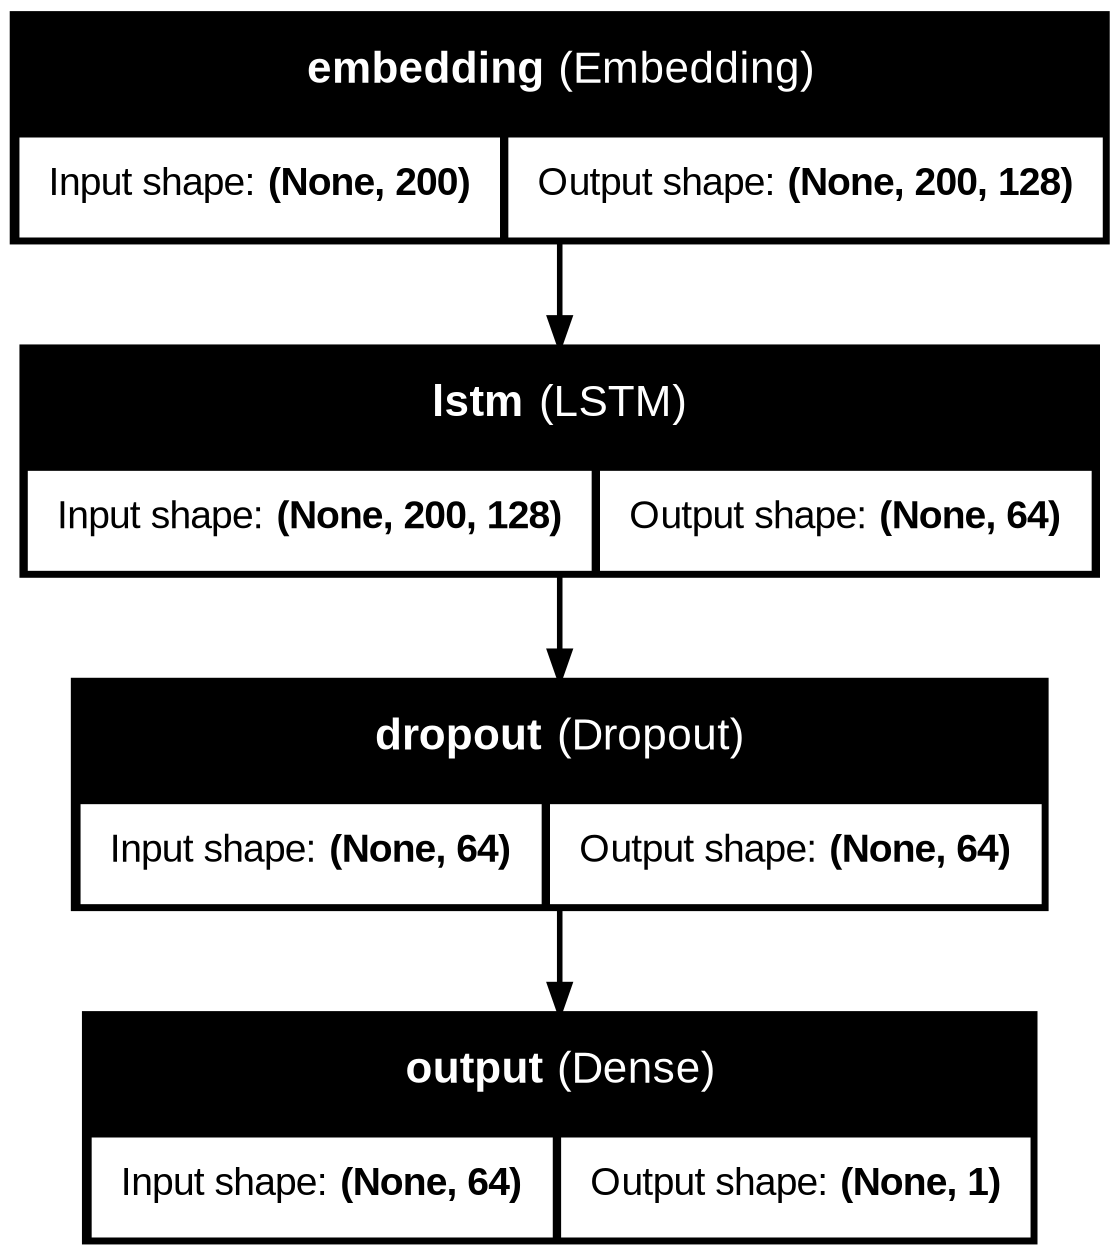

In [13]:
print("PART B  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

# Model architecture diagram (needs pydot + graphviz, available in Colab)
try:
    from IPython.display import Image, display
    keras.utils.plot_model(model, to_file="lstm_model.png", show_shapes=True, show_layer_names=True)
    display(Image("lstm_model.png"))
except Exception as e:
    print("Architecture diagram skipped:", e)

---
## PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

In [14]:
print("PART C  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

EPOCHS     = 5
BATCH_SIZE = 128

history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=EPOCHS,
                    batch_size=BATCH_SIZE,
                    verbose=1)

PART C  |  Roll No(s): 24BAD097
------------------------------------------------------------
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7440 - loss: 0.5109 - val_accuracy: 0.8474 - val_loss: 0.3770
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.8740 - loss: 0.3159 - val_accuracy: 0.8618 - val_loss: 0.3541
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9050 - loss: 0.2539 - val_accuracy: 0.8124 - val_loss: 0.4173
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9141 - loss: 0.2319 - val_accuracy: 0.8104 - val_loss: 0.4410
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9236 - loss: 0.2040 - val_accuracy: 0.7926 - val_loss: 0.4941


In [15]:
print("PART C  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

# Record training / validation accuracy and loss for every epoch
hist_df = pd.DataFrame(history.history)
hist_df.index = range(1, len(hist_df) + 1)
hist_df.index.name = "Epoch"
hist_df = hist_df.rename(columns={"loss": "Training Loss", "accuracy": "Training Accuracy",
                                    "val_loss": "Validation Loss", "val_accuracy": "Validation Accuracy"})
display(hist_df.round(4))

print(f"\nFinal Training Accuracy   : {history.history['accuracy'][-1]:.4f}")
print(f"Final Validation Accuracy : {history.history['val_accuracy'][-1]:.4f}")
print(f"Final Training Loss       : {history.history['loss'][-1]:.4f}")
print(f"Final Validation Loss     : {history.history['val_loss'][-1]:.4f}")

PART C  |  Roll No(s): 24BAD097
------------------------------------------------------------


,Training Accuracy,Training Loss,Validation Accuracy,Validation Loss
Epoch,,,,
1,0.7440,0.5109,0.8474,0.3770
2,0.8740,0.3159,0.8618,0.3541
3,0.9050,0.2539,0.8124,0.4173
4,0.9141,0.2319,0.8104,0.4410
5,0.9236,0.2040,0.7926,0.4941



Final Training Accuracy   : 0.9236
Final Validation Accuracy : 0.7926
Final Training Loss       : 0.2040
Final Validation Loss     : 0.4941


In [16]:
print("PART C  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

# Evaluate on the test dataset
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")

y_prob = model.predict(X_test, batch_size=256, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

print("\n----- Evaluation Metrics (Test set) -----")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

PART C  |  Roll No(s): 24BAD097
------------------------------------------------------------
Test Loss     : 0.5126
Test Accuracy : 0.7745

----- Evaluation Metrics (Test set) -----
Accuracy  : 0.7745
Precision : 0.7139
Recall    : 0.9161
F1-score  : 0.8025

Classification report:

              precision    recall  f1-score   support

    Negative       0.88      0.63      0.74     12500
    Positive       0.71      0.92      0.80     12500

    accuracy                           0.77     25000
   macro avg       0.80      0.77      0.77     25000
weighted avg       0.80      0.77      0.77     25000



PART C  |  Roll No(s): 24BAD097
------------------------------------------------------------


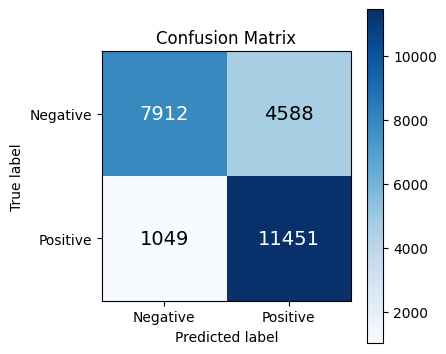

True Negatives : 7912
False Positives: 4588
False Negatives: 1049
True Positives : 11451


In [17]:
print("PART C  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative", "Positive"]); ax.set_yticklabels(["Negative", "Positive"])
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.colorbar(im); plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}\nFalse Positives: {fp}\nFalse Negatives: {fn}\nTrue Positives : {tp}")

PART C  |  Roll No(s): 24BAD097
------------------------------------------------------------


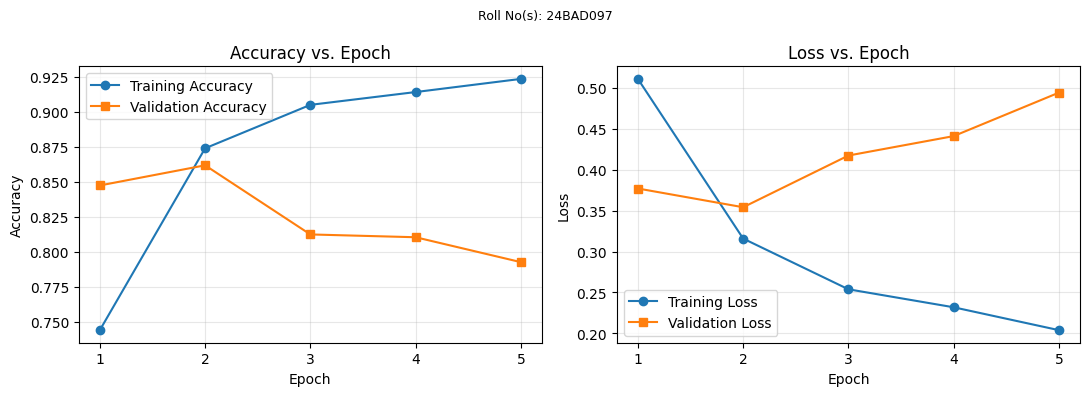

In [18]:
print("PART C  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

# Accuracy vs Epoch and Loss vs Epoch
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"],     "o-", label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], "s-", label="Validation Accuracy")
plt.title("Accuracy vs. Epoch"); plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.xticks(list(epochs_range)); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"],     "o-", label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], "s-", label="Validation Loss")
plt.title("Loss vs. Epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.xticks(list(epochs_range)); plt.legend(); plt.grid(alpha=0.3)

plt.suptitle(f"Roll No(s): {ROLL_NOS}", fontsize=9)
plt.tight_layout(); plt.show()

---
## PART D: SENTIMENT PREDICTION AND DEEP LEARNING EXPERIMENT MANAGEMENT

In [19]:
print("PART D  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

def predict_sentiment(review, threshold=0.5):
    """Preprocess -> tokenize -> encode (same vocab) -> pad -> predict."""
    tokens = clean_text(review).split()                       # same cleaning + tokenization
    seq    = [encode(tokens)]                                 # same vocabulary as training
    padded = keras.utils.pad_sequences(seq, maxlen=MAX_LEN, padding="pre", truncating="post")
    prob   = float(model.predict(padded, verbose=0)[0][0])
    label  = "Positive" if prob >= threshold else "Negative"
    return label, prob

# New review sentences with their expected sentiment
samples = [
    ("This movie was absolutely fantastic, the acting and story were brilliant!", "Positive"),
    ("A wonderful and heartwarming film. I loved every minute of it.",            "Positive"),
    ("One of the best movies I have seen this year, highly recommended.",         "Positive"),
    ("The plot was boring and the acting was terrible. Complete waste of time.",  "Negative"),
    ("I hated this film. The script was awful and the ending made no sense.",     "Negative"),
    ("Worst movie ever, extremely disappointing and painfully slow.",             "Negative"),
    ("The film started slow but turned into a gripping and emotional masterpiece.", "Positive"),
    ("The movie is not good at all, I would not watch it again.",                 "Negative"),
]

rows = []
for text, expected in samples:
    pred, prob = predict_sentiment(text)
    rows.append({"Review": text, "Expected": expected, "Predicted": pred,
                 "P(Positive)": round(prob, 4), "Match": "✔" if pred == expected else "✘"})

results_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
display(results_df)

correct = (results_df["Expected"] == results_df["Predicted"]).sum()
print(f"\nCorrect predictions: {correct}/{len(results_df)}  ({100*correct/len(results_df):.1f}%)")

PART D  |  Roll No(s): 24BAD097
------------------------------------------------------------


,Review,Expected,Predicted,P(Positive),Match
0,"This movie was absolutely fantastic, the acting and story were brilliant!",Positive,Positive,0.8796,✔
1,A wonderful and heartwarming film. I loved every minute of it.,Positive,Positive,0.9568,✔
2,"One of the best movies I have seen this year, highly recommended.",Positive,Positive,0.9981,✔
3,The plot was boring and the acting was terrible. Complete waste of time.,Negative,Negative,0.0068,✔
4,I hated this film. The script was awful and the ending made no sense.,Negative,Negative,0.1394,✔
5,"Worst movie ever, extremely disappointing and painfully slow.",Negative,Negative,0.0218,✔
6,The film started slow but turned into a gripping and emotional masterpiece.,Positive,Positive,0.9770,✔
7,"The movie is not good at all, I would not watch it again.",Negative,Positive,0.6741,✘



Correct predictions: 7/8  (87.5%)


In [20]:
print("PART D  |  Roll No(s):", ROLL_NOS)
print("-" * 60)

# Try your own reviews
your_reviews = [
    "An average movie, some scenes were good but overall it was disappointing.",
    "Great direction and superb performances by the entire cast!",
]
for r in your_reviews:
    label, prob = predict_sentiment(r)
    print(f"{label:8s} (P(pos)={prob:.3f})  <-  {r}")

PART D  |  Roll No(s): 24BAD097
------------------------------------------------------------
Negative (P(pos)=0.268)  <-  An average movie, some scenes were good but overall it was disappointing.
Positive (P(pos)=0.912)  <-  Great direction and superb performances by the entire cast!


In [21]:
# Save the trained model and vocabulary (for GitHub upload / reuse)
import json
model.save("lstm_sentiment_model.keras")
with open("word_index.json", "w") as f:
    json.dump(word_index, f)
print("Saved: lstm_sentiment_model.keras, word_index.json")

Saved: lstm_sentiment_model.keras, word_index.json
